# GRADIEND quickstart: singular vs plural pronouns

[GRADIEND](https://arxiv.org/abs/2502.01406) learns a *feature* inside a language model from its gradients.
A feature is the difference between two classes of words the model can predict. Here the classes are **third-person singular** pronouns (*he, she, it*) and **third-person plural** (*they*), and the model is BERT.

The workflow has four steps, and every notebook in this folder follows it:

1. **Data:** sentences in which a word of one class is masked.
2. **Train:** GRADIEND encodes the gradient difference between the word and its alternative from the other class in one feature neuron.
3. **Check:** the encoder should give the two classes opposite values.
4. **Rewrite:** the decoder turns the feature into a weight update of the base model.

```
pip install gradiend[recommended]
```

In [1]:
import sys

if "google.colab" in sys.modules:  # on Colab: install the package first
    !pip install -q "gradiend[recommended]"
    import plotly.io as pio

    pio.renderers.default = "colab"  # Colab cannot show plotly's default (JSON) output; this makes interactive plots render

In [2]:
import transformers

transformers.logging.set_verbosity_error()  # quiet model-loading messages

MODEL = "bert-base-cased"  # any masked language model, e.g. "distilbert-base-cased" or "roberta-base"

## 1. Data

`TextPredictionDataCreator` scans a text corpus for the target words of each class (a `TextFilterConfig`) and masks them.
Each row keeps the masked text and the original word (`label`); the alternative is a word of the other class.
The creator also returns *neutral* text without any target word, which we use later to check that the feature leaves other text alone.
We take sentences from Wikipedia (wikitext). To skip this step, the result is published as `aieng-lab/en-pronouns` and `aieng-lab/en-pronoun-neutral` on the Hugging Face Hub.

In [3]:
from gradiend import TextFilterConfig, TextPredictionDataCreator, TextPreprocessConfig

creator = TextPredictionDataCreator(
    base_data="Salesforce/wikitext", hf_config="wikitext-103-raw-v1", base_max_size=300_000,
    preprocess=TextPreprocessConfig(split_to_sentences=True, min_chars=40, max_chars=250),
    feature_targets=[TextFilterConfig(id="3SG", targets=["he", "she", "it"]), TextFilterConfig(id="3PL", targets=["they"])],
)
training = creator.generate_training_data(max_size_per_class=2500)
neutral = creator.generate_neutral_data(max_size=5000)

training["3SG"][["masked", "label"]].head(3)

2026-10-20 10:07:27 - WARNING - Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.


2026-10-20 10:07:41 - INFO -   3SG: 2500/2500 matches (9.08% of sentences scanned)


2026-10-20 10:07:41 - INFO -   3PL: 2500/2500 matches (1.99% of sentences scanned)


2026-10-20 10:07:41 - INFO - Overall: 5000/5000 (100.0%)


2026-10-20 10:07:41 - INFO - Training filter stats (instances per group): {'3SG': 2500, '3PL': 2500}


2026-10-20 10:07:41 - INFO - Match rate per class (fraction of sentences scanned): {'3SG': '9.08%', '3PL': '1.99%'}


2026-10-20 10:07:41 - INFO - Neutral filter stats: {'kept': 5000, 'excluded': 1621, 'total': 6621} (success rate: 0.76)


,masked,label
0,"T 'cha Dunlevy , a writer for the Montreal Gaz...",it
1,""" Popdust reported that "" this is Jay at his m...",he
2,Ferdinand records several complaints that his ...,it


## 2. Train

GRADIEND compares the base model's gradient when it predicts the original word with the gradient for the alternative (*he* vs *they*) and learns to encode this difference in **one feature neuron**.
Pruning keeps only the base-model weights that matter most, which keeps the training small. On a GPU this takes a few minutes.

2026-10-20 10:07:42 - INFO - Seed 0: starting training with output_dir=runs/quickstart/3SG_3PL/seeds/seed_0


2026-10-20 10:07:42 - INFO - Inferred decoder eval targets for 3SG_3PL: {'3SG': ['she', 'he', 'He', 'It', 'She', 'it', 'IT'], '3PL': ['THEY', 'they', 'They']}


2026-10-20 10:07:44 - INFO - Excluded 5 non-backbone (head) parameter(s); names: ['cls.predictions.bias', 'cls.predictions.transform.dense.weight', 'cls.predictions.transform.dense.bias', 'cls.predictions.transform.LayerNorm.weight', 'cls.predictions.transform.LayerNorm.bias']


2026-10-20 10:07:44 - INFO - Set feature_class_encoding_direction: {'3SG': 1, '3PL': -1}


2026-10-20 10:07:44 - INFO - Streaming pre-prune: collecting top-1,077,197 over 107,719,680 input dimensions from 16 sample(s).


...

2026-10-20 10:10:57 - INFO - Selected best seed=0 -> runs/quickstart/3SG_3PL/model


2026-10-20 10:10:57 - INFO - Wrote full training stats to runs/quickstart/3SG_3PL/model/training.json


2026-10-20 10:10:58 - INFO - Saved convergence plot: runs/quickstart/3SG_3PL/training_convergence.png


2026-10-20 10:10:58 - INFO - Saved training convergence plot: runs/quickstart/3SG_3PL/training_convergence.png


2026-10-20 10:10:58 - INFO - Saved convergence plot: runs/quickstart/3SG_3PL/training_convergence.png


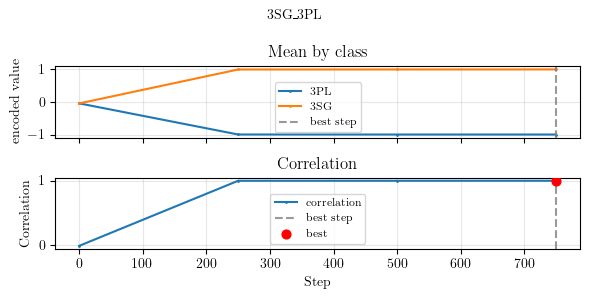

In [4]:
from gradiend import PostPruneConfig, PrePruneConfig, TextPredictionTrainer, TrainingArguments

args = TrainingArguments(
    experiment_dir="runs/quickstart", learning_rate=1e-4, train_batch_size=16, max_steps=1000, eval_steps=250,
    max_seeds=5, min_convergent_seeds=1, encoder_eval_max_size=50, decoder_eval_max_size_training_like=100,
    decoder_eval_max_size_neutral=500,
    pre_prune_config=PrePruneConfig(n_samples=16, topk=0.01), post_prune_config=PostPruneConfig(topk=0.05),
)
trainer = TextPredictionTrainer(
    model=MODEL, run_id="3SG_3PL", data=training, target_classes=["3SG", "3PL"], eval_neutral_data=neutral, args=args,
)
trainer.train()
_ = trainer.plot_training_convergence()

The plot shows how the encoder develops on validation data: the mean encoded value of each class (top) and the correlation between the encoded value and the class (bottom).
GRADIEND has converged once the two classes sit at opposite values and the correlation is close to 1.
Training is random: if a seed does not converge, GRADIEND trains the next one (`max_seeds`) until `min_convergent_seeds` have converged, and the plot shows the selected seed.

## 3. Check the feature

On held-out examples, the encoder should map the two classes to opposite values (+1 / -1) and neutral text to about 0.

2026-10-20 10:10:59 - INFO - Inferred decoder eval targets for 3SG_3PL: {'3SG': ['she', 'he', 'He', 'It', 'She', 'it', 'IT'], '3PL': ['THEY', 'they', 'They']}


2026-10-20 10:10:59 - INFO - Computing encoder analysis for all variants


2026-10-20 10:10:59 - INFO - Encoding training data (max_size=50, source=alternative, size=100)


2026-10-20 10:11:04 - INFO - Encoding neutral training masked data (max_size=50, size=100)


2026-10-20 10:11:06 - INFO - Encoding neutral dataset data (size=5000)


2026-10-20 10:11:07 - INFO - Saved encoder analysis results to runs/quickstart/3SG_3PL/encoded_values_max_size_50_split_test.csv


2026-10-20 10:11:08 - INFO - Saved encoder distribution plot: runs/quickstart/3SG_3PL/encoder_analysis_max_size_50_split_test.png


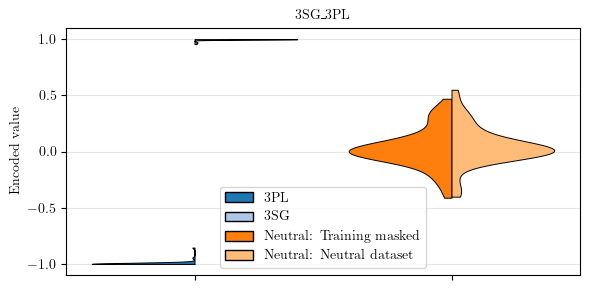

correlation: 0.9998661119072142 | mean by class: {'3PL': -0.995695229768753, '3SG': 0.9977486455440521}


In [5]:
enc = trainer.evaluate_encoder(plot=True, return_df=True)
print("correlation:", enc["correlation"], "| mean by class:", enc["mean_by_feature_class"])

Every point is one example; hover to read the sentence and spot outliers.

In [6]:
trainer.plot_encoder_scatter(
    encoder_df=enc["encoder_df"], max_points=500, color_by="label",
    label_name_mapping={"1.0": "3SG", "-1.0": "3PL", "0.0": "neutral"}, title="Encoded values",
);

2026-10-20 10:11:08 - INFO - Saved encoder scatter: runs/quickstart/3SG_3PL/encoder_analysis_scatter.html


## 4. Rewrite the model

The decoder maps a feature value back to a weight update of the base model. `evaluate_decoder` applies the update with increasing strength (x-axis, labelled *learning rate*):
too weak and nothing changes, too strong and the language model breaks (the language modelling score LMS, top, drops).
The star marks the strength that shifts the pronoun probabilities most while LMS stays close to the base model. `rewrite_base_model` returns the model with that update.

2026-10-20 10:11:08 - INFO - Starting decoder evaluation with part=decoder


2026-10-20 10:11:08 - INFO - Decoder eval feature_factors=[1.0] class_to_ff={'3SG': 1.0, '3PL': -1.0} source=alternative


2026-10-20 10:12:49 - INFO - Saved probability shifts plot to runs/quickstart/3SG_3PL/3SG_3PL/decoder_probability_shifts_3SG.png


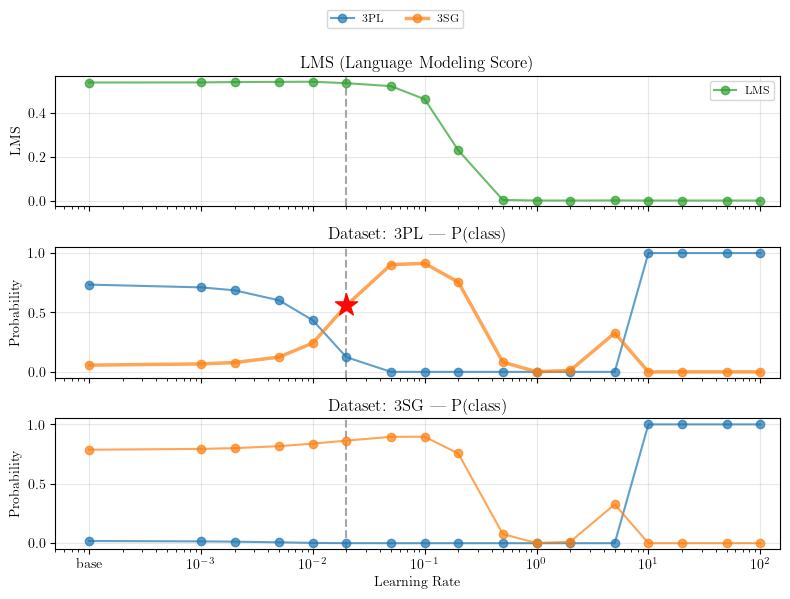

In [7]:
dec = trainer.evaluate_decoder(plot=True, target_class="3SG")
changed_model = trainer.rewrite_base_model(decoder_results=dec, target_class="3SG")

Compare the predictions of both models: the rewritten model prefers singular pronouns, even where the base model predicts *they*.

In [8]:
from transformers import AutoModelForMaskedLM, AutoTokenizer, pipeline

tokenizer = AutoTokenizer.from_pretrained(MODEL)
mask = tokenizer.mask_token
for name, model in [("base", AutoModelForMaskedLM.from_pretrained(MODEL)), ("rewritten (3SG)", changed_model)]:
    fill = pipeline("fill-mask", model=model, tokenizer=tokenizer)
    for text in [f"The doctor said that {mask} was exhausted.", f"The doctors said that {mask} were exhausted."]:
        print(name, "|", text, [(r["token_str"], round(r["score"], 3)) for r in fill(text, top_k=4)])

base | The doctor said that [MASK] was exhausted. [('he', 0.522), ('she', 0.323), ('I', 0.039), ('it', 0.006)]
base | The doctors said that [MASK] were exhausted. [('they', 0.916), ('we', 0.024), ('both', 0.016), ('people', 0.007)]
rewritten (3SG) | The doctor said that [MASK] was exhausted. [('he', 0.614), ('she', 0.243), ('it', 0.042), ('I', 0.018)]
rewritten (3SG) | The doctors said that [MASK] were exhausted. [('he', 0.542), ('she', 0.18), ('they', 0.066), ('it', 0.022)]
